In [5]:
from utils.data_io import iter_signals_and_targets
from utils.constants import *
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import pandas as pd
from collections import Counter

In [6]:
id, signal, labels = next(iter_signals_and_targets(split="train"))
signal = signal.reshape((5,EPOCH_DURATION*SAMPLING_RATE,-1))

In [7]:
from collections import defaultdict
import numpy as np

patient_epochs = defaultdict(int)

for pid, signal, labels in iter_signals_and_targets():
    n_ch, n_samples = signal.shape
    n_ep_sig = n_samples // (EPOCH_DURATION * SAMPLING_RATE)
    n_ep_lab = len(labels)

    print(f"Patient {pid}: {n_ch} ch | {n_ep_sig} epochs (signal) | {n_ep_lab} labels"
          + (" ⚠️ mismatch" if n_ep_sig != n_ep_lab else ""))

    patient_epochs[pid] = n_ep_lab

print("\nTotal epochs:", sum(patient_epochs.values()))


Patient 0: 5 ch | 969 epochs (signal) | 969 labels
Patient 1: 5 ch | 1011 epochs (signal) | 1011 labels
Patient 2: 5 ch | 620 epochs (signal) | 620 labels
Patient 3: 5 ch | 990 epochs (signal) | 990 labels
Patient 4: 5 ch | 929 epochs (signal) | 929 labels


Patient 5: 5 ch | 957 epochs (signal) | 957 labels
Patient 6: 5 ch | 975 epochs (signal) | 975 labels
Patient 7: 5 ch | 982 epochs (signal) | 982 labels

Total epochs: 7433


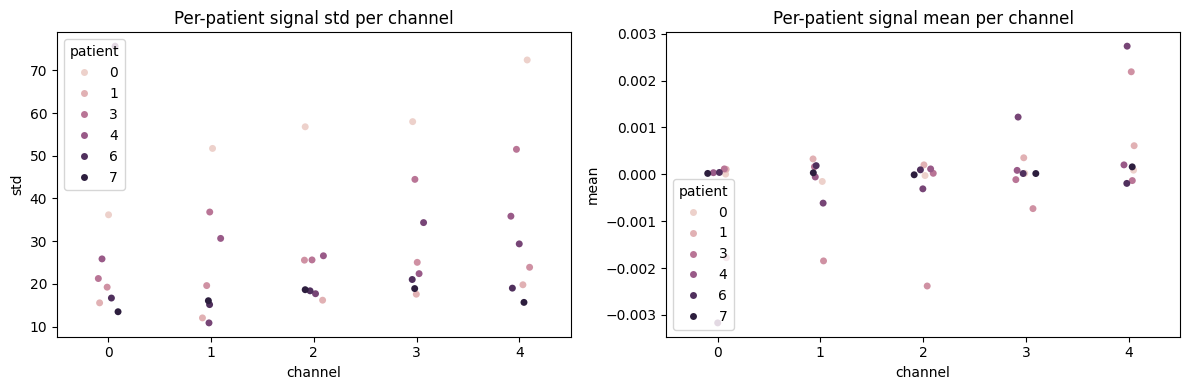

In [8]:
stats = []

for pid, signal, labels in iter_signals_and_targets():
    ch_means = signal.mean(axis=1)
    ch_stds  = signal.std(axis=1)
    ch_ptp   = np.ptp(signal, axis=1)  # max - min
    for ch in range(signal.shape[0]):
        stats.append({
            "patient": pid,
            "channel": ch,
            "mean": ch_means[ch],
            "std": ch_stds[ch],
            "ptp": ch_ptp[ch]
        })

df_stats = pd.DataFrame(stats)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=False)

sns.stripplot(data=df_stats, x="channel", y="std", hue="patient", ax=axes[0])
axes[0].set_title("Per-patient signal std per channel")

sns.stripplot(data=df_stats, x="channel", y="mean", hue="patient", ax=axes[1])
axes[1].set_title("Per-patient signal mean per channel")

plt.tight_layout()
plt.show()


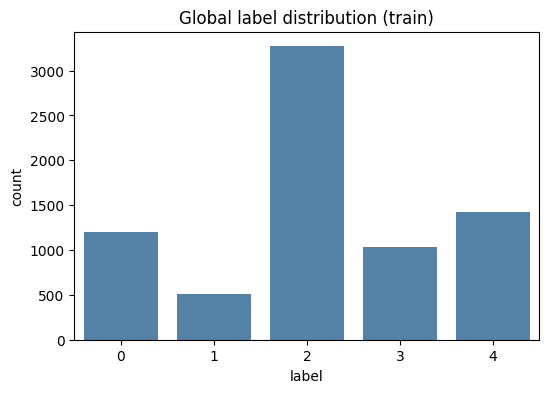

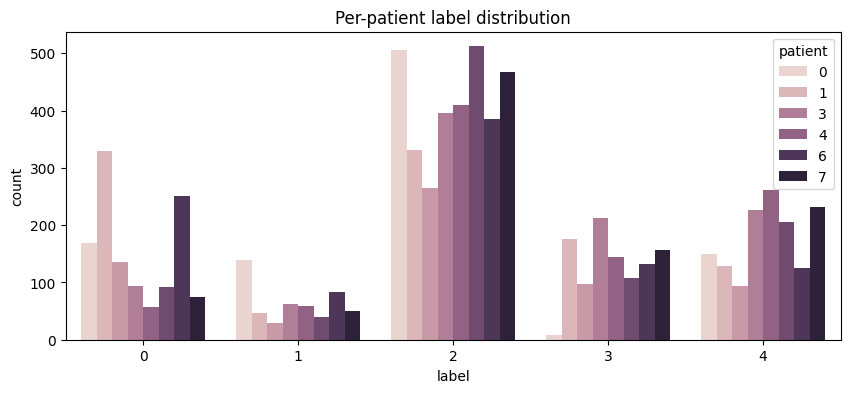

In [9]:
# Collect label counts
records = []
for pid, _, labels in iter_signals_and_targets():
    counts = Counter(labels)
    for label, n in counts.items():
        records.append({"patient": pid, "label": label, "count": n})

df_labels = pd.DataFrame(records)

# Global distribution
plt.figure(figsize=(6,4))
sns.barplot(data=df_labels.groupby("label")["count"].sum().reset_index(),
            x="label", y="count", color="steelblue")
plt.title("Global label distribution (train)")
plt.show()

# Per-patient distribution
plt.figure(figsize=(10,4))
sns.barplot(data=df_labels, x="label", y="count", hue="patient")
plt.title("Per-patient label distribution")
plt.show()


In [10]:
pid, signal, labels = next(iter_signals_and_targets())

samples_per_epoch = EPOCH_DURATION * SAMPLING_RATE
signal = signal.reshape(5, len(labels), samples_per_epoch)

stages = np.unique(labels)
example_idx = {stage: np.where(labels == stage)[0][0] for stage in stages}


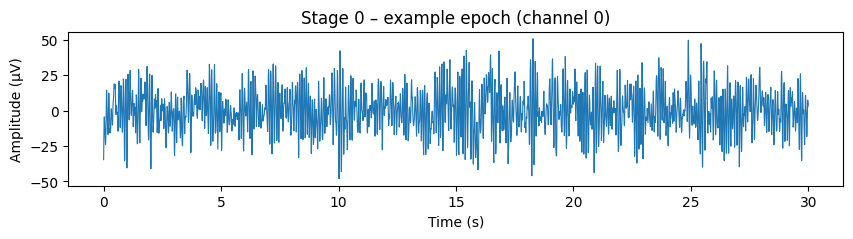

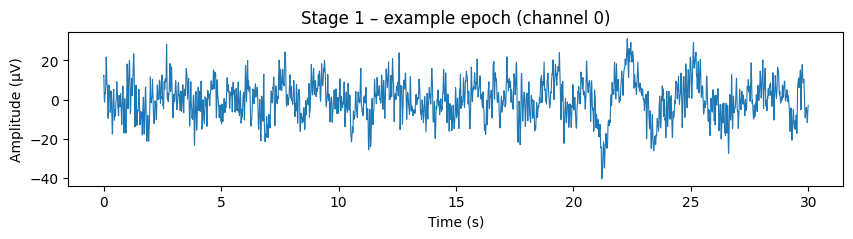

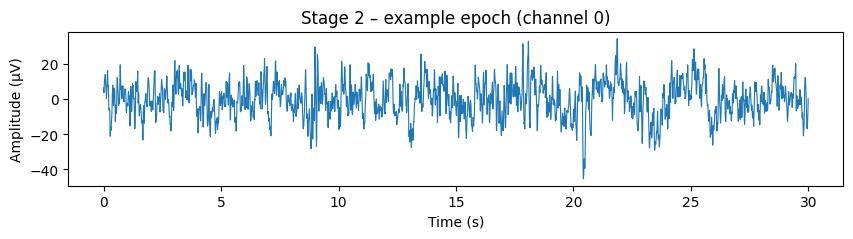

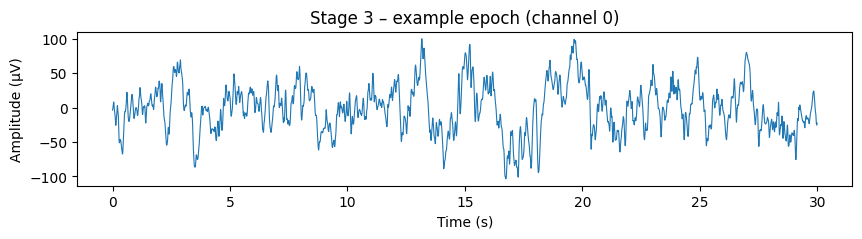

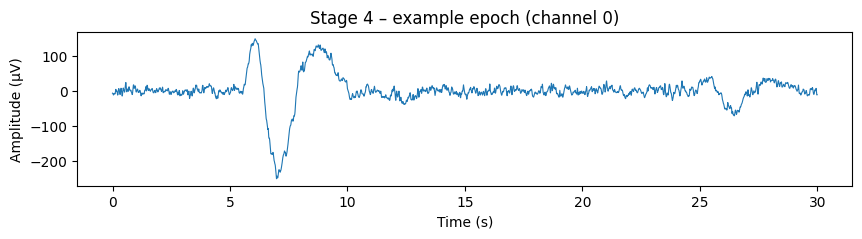

In [11]:
t = np.arange(samples_per_epoch) / SAMPLING_RATE
for stage, idx in example_idx.items():
    plt.figure(figsize=(10, 2))
    plt.plot(t, signal[0, idx], lw=0.8)
    plt.title(f"Stage {stage} – example epoch (channel 0)")
    plt.xlabel("Time (s)")
    plt.ylabel("Amplitude (µV)")
    plt.show()


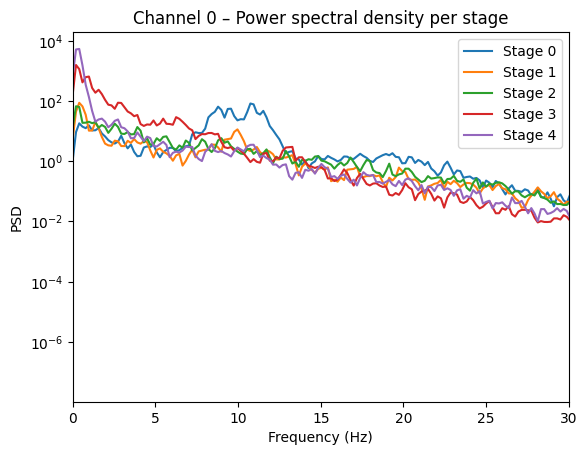

In [12]:
from scipy.signal import welch

for stage, idx in example_idx.items():
    f, Pxx = welch(signal[0, idx], fs=SAMPLING_RATE, nperseg=512)
    plt.semilogy(f, Pxx, label=f"Stage {stage}")

plt.xlim(0, 30)
plt.xlabel("Frequency (Hz)")
plt.ylabel("PSD")
plt.title("Channel 0 – Power spectral density per stage")
plt.legend()
plt.show()


In [23]:
from scipy.integrate import simpson

def normalize_per_patient(signal):
    # signal shape: (n_channels, n_samples)
    mean = signal.mean(axis=1, keepdims=True)
    std  = signal.std(axis=1, keepdims=True)
    return (signal - mean) / std

def bandpower(data, sf, band):
    f, Pxx = welch(data, sf, nperseg=512)
    idx = np.logical_and(f >= band[0], f <= band[1])
    return simpson(Pxx[idx], f[idx])

def extract_epoch_features(signal, sf=SAMPLING_RATE):
    """
    signal: (n_channels, n_samples_per_epoch)
    returns dict of summary features averaged across channels
    """
    feats = {}
    means, stds, ptps = signal.mean(1), signal.std(1), np.ptp(signal,1)
    bands = {"delta": (0.5,4), "theta": (4,8), "alpha": (8,12), "beta": (12,30)}
    bp = {b: np.mean([bandpower(ch, sf, rng) for ch in signal]) for b, rng in bands.items()}

    feats.update({
        "mean": means.mean(),
        "std": stds.mean(),
        "ptp": ptps.mean(),
        **bp,
        "ratio_delta_theta": bp["delta"]/bp["theta"],
        "ratio_alpha_beta": bp["alpha"]/bp["beta"],
    })
    return feats

# --------------------------------------------
# Build per-epoch feature dataframe (one patient example)
pid, signal, labels = next(iter_signals_and_targets())
signal = normalize_per_patient(signal)
samples_per_epoch = EPOCH_DURATION * SAMPLING_RATE
n_epochs = len(labels)
signal_epochs = signal.reshape(5, n_epochs, samples_per_epoch)

feat_list = [extract_epoch_features(signal_epochs[:, i, :]) for i in range(n_epochs)]
df_feats = pd.DataFrame(feat_list)
df_feats["label"] = labels
df_feats.head()


,mean,std,ptp,delta,theta,alpha,beta,ratio_delta_theta,ratio_alpha_beta,label
0,-0.002056,0.281659,1.955991,0.013906,0.004659,0.054857,0.005557,2.984968,9.872243,0
1,0.000493,0.262859,1.850865,0.013371,0.003588,0.042329,0.004262,3.726632,9.931194,0
2,0.000763,0.261666,1.680616,0.010307,0.003828,0.035557,0.003666,2.692178,9.699080,0
3,-0.001942,0.241289,1.666237,0.007767,0.002969,0.035326,0.003493,2.615801,10.113097,0
4,0.002725,0.240692,1.793912,0.012277,0.003476,0.027376,0.003210,3.532236,8.528230,0


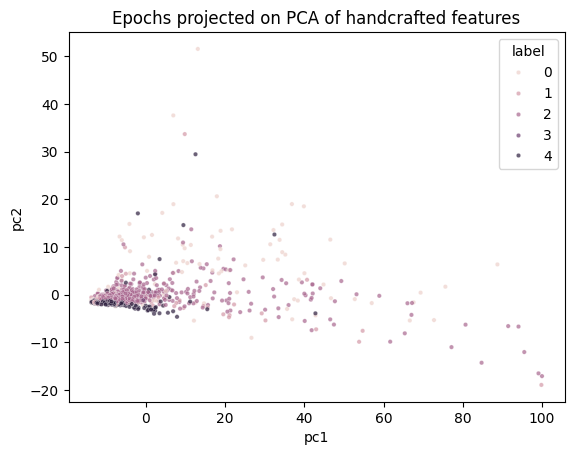

In [25]:
from sklearn.decomposition import PCA
import seaborn as sns
import matplotlib.pyplot as plt

X = df_feats.drop(columns="label").values
y = df_feats["label"]

X_pca = PCA(n_components=2).fit_transform(X)
df_plot = pd.DataFrame(X_pca, columns=["pc1","pc2"])
df_plot["label"] = y

sns.scatterplot(data=df_plot, x="pc1", y="pc2", hue="label", s=10, alpha=0.7)
plt.title("Epochs projected on PCA of handcrafted features")
plt.show()


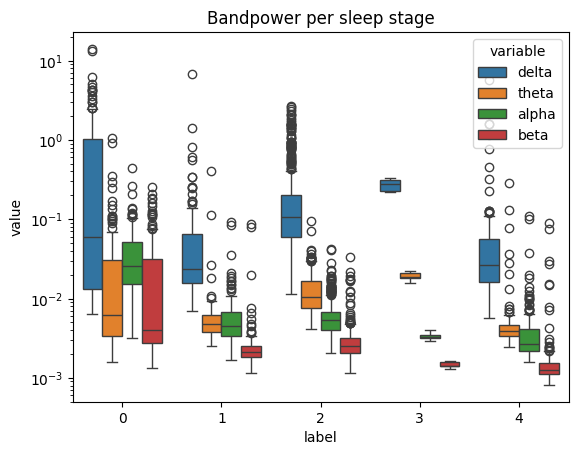

In [26]:
melted = df_feats.melt(id_vars="label", value_vars=["delta","theta","alpha","beta"])
sns.boxplot(data=melted, x="label", y="value", hue="variable")
plt.title("Bandpower per sleep stage")
plt.yscale("log")
plt.show()


# Epoch Drift

In [1]:
from utils.data_io import iter_signals_and_targets
from utils.constants import *
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import pandas as pd
from collections import Counter
from features.epoch_features import EpochFeaturesPower

In [2]:
fe = EpochFeaturesPower(power_bands=None,seed=42, test_size=0.2, log_bandpower=True, include_hjorth=True, include_entropy=True, include_epoch_drift=True)

In [3]:
data = iter_signals_and_targets()
features = fe(data, default_data_conf, save=False)
X = features["X_train"]
y = features["y_train"]


In [4]:
df = pd.concat([X, y.rename("label")], axis=1)

/tmp/ipykernel_15230/1469711281.py:1: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar='sd'` for the same effect.

  sns.barplot(x="label", y="epoch_drift_prev", data=df, estimator="mean", ci="sd")


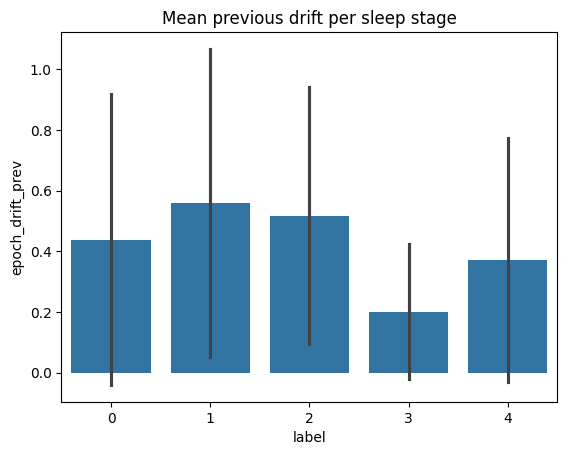

/tmp/ipykernel_15230/1469711281.py:5: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar='sd'` for the same effect.

  sns.barplot(x="label", y="epoch_drift_next", data=df, estimator="mean", ci="sd")


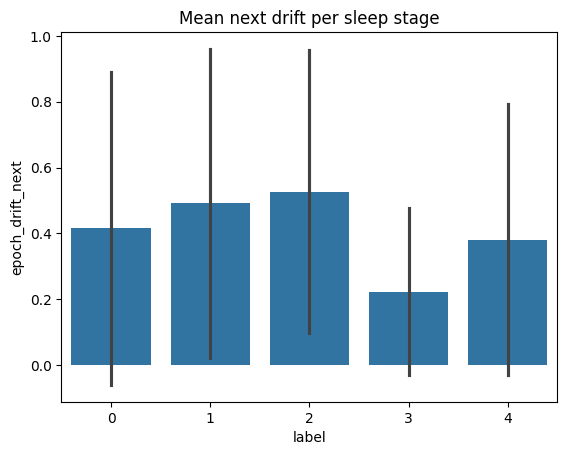

In [5]:
sns.barplot(x="label", y="epoch_drift_prev", data=df, estimator="mean", ci="sd")
plt.title("Mean previous drift per sleep stage")
plt.show()

sns.barplot(x="label", y="epoch_drift_next", data=df, estimator="mean", ci="sd")
plt.title("Mean next drift per sleep stage")
plt.show()


Text(0.5, 0, 'Sleep stage')

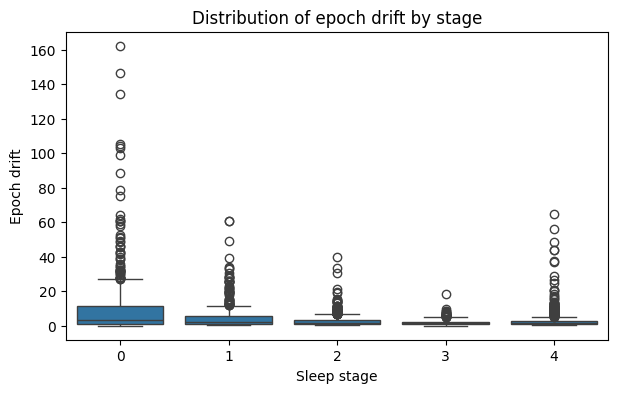

In [11]:
plt.figure(figsize=(7,4))
sns.boxplot(x="label", y="epoch_drift", data=df)
plt.title("Distribution of epoch drift by stage")
plt.ylabel("Epoch drift")
plt.xlabel("Sleep stage")